<a href="https://colab.research.google.com/github/User0SE4/Knowledge_Distillation/blob/main/Knowledge_Distillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Getting Started

## Section 1 - Environment & Reproducibility
Set up Colab, GPU, fixed seed, Google Drive for persistent checkpoints,
and a single centralized experiment config reused by every experiment.

In [1]:
import os, random, json
import numpy as np
import torch
import torchvision
from torch.utils.data import DataLoader, Subset

In [2]:

# Persistent storage so a Colab disconnect does not wipe trained models
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

project_root = "/content/drive/MyDrive/MASTER_VMI_2026_2027/Methodes et Imagerie Thematiques/Knowledge_Distillation"
dirs = {name: os.path.join(project_root, name)
        for name in ["data", "checkpoints", "results", "figures", "configs"]}
for directory in dirs.values():
    os.makedirs(directory, exist_ok=True)
print("Project root:", project_root)

Mounted at /content/drive
Project root: /content/drive/MyDrive/MASTER_VMI_2026_2027/Methodes et Imagerie Thematiques/Knowledge_Distillation


In [3]:


# Reproducibility: seed fixes the data split and model init.
# cudnn.benchmark stays ON for speed (we trade strict determinism for time).
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [4]:
# Central config reused by all experiments (one source of truth)
config = {
    "resolution": 96,     # resize CIFAR 32->96 (no model change); revisit after timing test
    "batch_size": 128,
    "num_workers": 2,
    "seed": SEED,
    "temperature": 2.0,   # KD softmax temperature
    "alpha": 0.5,         # KD vs CE weight (score-level distillation)
    "lambda_feat": 1.0,   # feature loss weight (feature-level distillation)
    "learning_rate": 1e-3,
    "epochs": 3,          # starting budget; adjust after the 1-epoch timing test
}
with open(os.path.join(dirs["configs"], "config.json"), "w") as file:
    json.dump(config, file, indent=2)
config

{'resolution': 96,
 'batch_size': 128,
 'num_workers': 2,
 'seed': 42,
 'temperature': 2.0,
 'alpha': 0.5,
 'lambda_feat': 1.0,
 'learning_rate': 0.001,
 'epochs': 3}

## Section 2 - CIFAR-10 (train:40k / val:10k /test 10k stratified)
Keep the official 10k test set. Split the official 50k training set into
40k train / 10k validation with a stratified, seeded split (same sets for
every model). Use ImageNet normalization since the ResNets are pretrained.

In [5]:
import torchvision.transforms as transforms
from sklearn.model_selection import StratifiedShuffleSplit

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
image_size = config["resolution"]

# Train transforms = light augmentation; eval transforms (wihout transformations)
train_transform = transforms.Compose([
    transforms.Resize(image_size), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

data_dir = dirs["data"]  # CIFAR-10 stored under the project folder on Drive
# Two views of the SAME 50k train set: one augmented (for train), one plain (for val)
train_full_augmented = torchvision.datasets.CIFAR10(data_dir, train=True,  download=True, transform=train_transform)
train_full_plain     = torchvision.datasets.CIFAR10(data_dir, train=True,  download=True, transform=eval_transform)
test_dataset         = torchvision.datasets.CIFAR10(data_dir, train=False, download=True, transform=eval_transform)

# Stratified 40k/10k split preserving class balance
targets = np.array(train_full_augmented.targets)
splitter = StratifiedShuffleSplit(n_splits=1, test_size=10000, random_state=SEED)
train_indices, val_indices = next(splitter.split(np.zeros(len(targets)), targets))

train_dataset = Subset(train_full_augmented, train_indices)  # augmented
val_dataset   = Subset(train_full_plain,     val_indices)    # not augmented

class_names = train_full_augmented.classes
print(f"Train/Val/Test: {len(train_dataset)} / {len(val_dataset)} / {len(test_dataset)}")

# Sanity check: class balance (expect ~4000 train / ~1000 val per class)
for name, indices in [("train", train_indices), ("val", val_indices)]:
    print(name, "class counts:", np.bincount(targets[indices], minlength=10).tolist())

def make_loader(dataset, shuffle):
    return DataLoader(dataset, batch_size=config["batch_size"], shuffle=shuffle,
                      num_workers=config["num_workers"], pin_memory=True)

train_loader = make_loader(train_dataset, True)
val_loader   = make_loader(val_dataset,   False)
test_loader  = make_loader(test_dataset,  False)

images, labels = next(iter(train_loader))
print("Batch:", images.shape, "| labels:", labels.shape, "| dtype:", images.dtype)

100%|██████████| 170M/170M [16:14<00:00, 175kB/s]


Train/Val/Test: 40000 / 10000 / 10000
train class counts: [4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000, 4000]
val class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Batch: torch.Size([128, 3, 96, 96]) | labels: torch.Size([128]) | dtype: torch.float32


## Section 3 - Architectures
Teacher = ResNet50 (ImageNet-pretrained). Students = ResNet18, one pretrained
and one from scratch. The final fully-connected layer is replaced to output
10 classes. We also inspect parameter counts and intermediate feature-map
shapes (needed later to align teacher/student features for feature-level KD).

In [6]:
import torch.nn as nn
from torchvision.models import resnet50, resnet18, ResNet50_Weights, ResNet18_Weights

NUM_CLASSES = 10

def build_resnet50_teacher(pretrained=True):
    weights = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    model = resnet50(weights=weights)
    # Replace the ImageNet classification head (1000 classes) by a CIFAR-10 head (10 classes)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def build_resnet18_student(pretrained=True):
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

In [7]:
teacher            = build_resnet50_teacher(pretrained=True).to(device)
student_pretrained = build_resnet18_student(pretrained=True).to(device)
student_scratch    = build_resnet18_student(pretrained=False).to(device)

#Number of parameters
def count_parameters(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for name, model in [("ResNet50 teacher", teacher),
                    ("ResNet18 student (pretrained)", student_pretrained),
                    ("ResNet18 student (scratch)", student_scratch)]:
    total, trainable = count_parameters(model)
    print(f"{name:32s} | total: {total:,} | trainable: {trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 150MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


ResNet50 teacher                 | total: 23,528,522 | trainable: 23,528,522
ResNet18 student (pretrained)    | total: 11,181,642 | trainable: 11,181,642
ResNet18 student (scratch)       | total: 11,181,642 | trainable: 11,181,642


In [8]:
# Capture the output shapes of layer3 and layer4 via forward hooks.
# Same input size -> same spatial dims, but channels differ between ResNet50 and ResNet18.
captured_shapes = {}

def make_shape_hook(key):
    def hook(module, inputs, output):
        captured_shapes[key] = tuple(output.shape)
    return hook

dummy_input = torch.randn(1, 3, config["resolution"], config["resolution"]).to(device)

for model_name, model in [("teacher (ResNet50)", teacher),
                          ("student (ResNet18)", student_pretrained)]:
    captured_shapes.clear()
    handle3 = model.layer3.register_forward_hook(make_shape_hook("layer3"))
    handle4 = model.layer4.register_forward_hook(make_shape_hook("layer4"))
    model.eval()
    with torch.no_grad():
        _ = model(dummy_input)
    handle3.remove(); handle4.remove()
    print(f"{model_name}: layer3 {captured_shapes['layer3']} | layer4 {captured_shapes['layer4']}")

teacher (ResNet50): layer3 (1, 1024, 6, 6) | layer4 (1, 2048, 3, 3)
student (ResNet18): layer3 (1, 256, 6, 6) | layer4 (1, 512, 3, 3)


## Section 4 : Shared functions
Reusable building blocks: one training epoch, evaluation (loss + accuracy,
used for both validation and test), checkpointing, and a `fit` loop that
trains, validates, logs history and saves the best checkpoint.

Distillation-specific losses are added later (Sections 7-8).

#Test on one epoch:
a kind of smoke test before test on larger number of epochs

In [9]:
import time

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)   # sum, not mean, to average correctly at the end
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

In [14]:
#For validation and test(same logic)
@torch.no_grad()   #For optimization
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, labels)
        running_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

In [15]:
#Checkpoints

def save_checkpoint(model, run_name, extra=None):
    path = os.path.join(dirs["checkpoints"], f"{run_name}.pth")
    payload = {"model_state": model.state_dict()}
    if extra:
        payload.update(extra)
    torch.save(payload, path)
    return path

def load_checkpoint(model, run_name, device):
    path = os.path.join(dirs["checkpoints"], f"{run_name}.pth")
    payload = torch.load(path, map_location=device)
    model.load_state_dict(payload["model_state"])
    return payload

In [18]:
def fit(model, train_loader, val_loader, config, run_name, epochs=None):
    n_epochs  = epochs if epochs is not None else config["epochs"]
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    for epoch in range(n_epochs):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc     = evaluate(model, val_loader, criterion, device)
        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint(model, f"{run_name}_best", {"epoch": epoch, "val_acc": val_acc})
        print(f"epoch {epoch+1}/{n_epochs} | "
              f"train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time()-start:.0f}s")
    return history, best_val_acc

## Section 5 - Teacher ResNet50 (T0)
First a 1-epoch timing test on CIFAR-10 to measure the real per-epoch cost,
then we fix the epoch budget for the whole study accordingly.

In [19]:
# One-epoch smoke test: tells us how expensive a full epoch is before committing a budget.
smoke_config = dict(config)
smoke_config["epochs"] = 1
smoke_history, _ = fit(teacher, train_loader, val_loader, smoke_config, run_name="T0_resnet50_smoke")

epoch 1/1 | train loss 0.281 acc 0.906 | val loss 0.337 acc 0.881 | 92s


In [20]:
config["epochs_pretrained"] = 5
config["epochs_scratch"]    = 10

**Pre-trained Teacher model**

In [21]:
# Rebuild a clean teacher so it is trained exactly epochs_pretrained epochs (reproducible run)
teacher = build_resnet50_teacher(pretrained=True).to(device)
teacher_history, teacher_best_val = fit(
    teacher, train_loader, val_loader, config,
    run_name="T0_resnet50", epochs=config["epochs_pretrained"])

# Final evaluation on the held-out test set, using the best checkpoint
load_checkpoint(teacher, "T0_resnet50_best", device)
test_loss, teacher_test_acc = evaluate(teacher, test_loader, nn.CrossEntropyLoss(), device)
print(f"Teacher T0 — best val acc: {teacher_best_val:.4f} | test acc: {teacher_test_acc:.4f}")

epoch 1/5 | train loss 0.400 acc 0.869 | val loss 0.317 acc 0.895 | 92s
epoch 2/5 | train loss 0.229 acc 0.922 | val loss 0.315 acc 0.893 | 91s
epoch 3/5 | train loss 0.174 acc 0.940 | val loss 0.265 acc 0.911 | 90s
epoch 4/5 | train loss 0.142 acc 0.952 | val loss 0.302 acc 0.902 | 90s
epoch 5/5 | train loss 0.117 acc 0.961 | val loss 0.285 acc 0.909 | 89s
Teacher T0 — best val acc: 0.9113 | test acc: 0.9084


In [22]:
results = {}  # run_name -> metrics, filled as we go (used for the final recap tables)

def record_result(run_name, best_val_acc, test_acc, extra=None):
    results[run_name] = {"best_val_acc": best_val_acc, "test_acc": test_acc}
    if extra:
        results[run_name].update(extra)

record_result("T0_teacher_resnet50", teacher_best_val, teacher_test_acc)
results

{'T0_teacher_resnet50': {'best_val_acc': 0.9113, 'test_acc': 0.9084}}

**Number of parameters of Teacher model**

In [25]:
n_weights = sum(
    p.numel()
    for name, p in teacher.named_parameters()
    if name.endswith("weight")
)

n_biases = sum(
    p.numel()
    for name, p in teacher.named_parameters()
    if name.endswith("bias")
)

print("Weights:", n_weights)
print("Biases:", n_biases)
print("Total:", n_weights + n_biases)

Weights: 23501952
Biases: 26570
Total: 23528522


## Section 6: ResNet18 baselines (no distillation)
Two ResNet18 students trained with cross-entropy only, used as references
(TP questions 2 and 5):
- **S1** : pretrained on ImageNet, fine-tuned on CIFAR-10 (Strategy 1 baseline).
- **S4** : trained from scratch on CIFAR-10 (Strategy 2 baseline).
These quantify the contribution of ImageNet pretraining before any distillation.

**Pre-trained Student (ResNet 18)**

In [23]:
student_s1 = build_resnet18_student(pretrained=True).to(device)
s1_history, s1_best_val = fit(student_s1, train_loader, val_loader, config,
                              run_name="S1_resnet18_pretrained", epochs=config["epochs_pretrained"])

load_checkpoint(student_s1, "S1_resnet18_pretrained_best", device)
_, s1_test_acc = evaluate(student_s1, test_loader, nn.CrossEntropyLoss(), device)
record_result("S1_resnet18_pretrained", s1_best_val, s1_test_acc)
print(f"S1 — best val: {s1_best_val:.4f} | test: {s1_test_acc:.4f}")

epoch 1/5 | train loss 0.550 acc 0.815 | val loss 0.522 acc 0.832 | 40s
epoch 2/5 | train loss 0.338 acc 0.885 | val loss 0.437 acc 0.856 | 41s
epoch 3/5 | train loss 0.263 acc 0.911 | val loss 0.387 acc 0.875 | 39s
epoch 4/5 | train loss 0.209 acc 0.929 | val loss 0.416 acc 0.866 | 38s
epoch 5/5 | train loss 0.185 acc 0.938 | val loss 0.411 acc 0.873 | 38s
S1 — best val: 0.8748 | test: 0.8721


**No pre-trained Student**

In [24]:
student_s4 = build_resnet18_student(pretrained=False).to(device)
s4_history, s4_best_val = fit(student_s4, train_loader, val_loader, config,
                              run_name="S4_resnet18_scratch", epochs=config["epochs_scratch"])

load_checkpoint(student_s4, "S4_resnet18_scratch_best", device)
_, s4_test_acc = evaluate(student_s4, test_loader, nn.CrossEntropyLoss(), device)
record_result("S4_resnet18_scratch", s4_best_val, s4_test_acc)
print(f"S4 — best val: {s4_best_val:.4f} | test: {s4_test_acc:.4f}")

epoch 1/10 | train loss 1.329 acc 0.518 | val loss 1.270 acc 0.561 | 37s
epoch 2/10 | train loss 0.897 acc 0.684 | val loss 0.984 acc 0.662 | 36s
epoch 3/10 | train loss 0.700 acc 0.754 | val loss 0.787 acc 0.724 | 38s
epoch 4/10 | train loss 0.576 acc 0.799 | val loss 0.740 acc 0.747 | 38s
epoch 5/10 | train loss 0.491 acc 0.830 | val loss 0.642 acc 0.782 | 37s
epoch 6/10 | train loss 0.422 acc 0.852 | val loss 0.610 acc 0.796 | 38s
epoch 7/10 | train loss 0.357 acc 0.875 | val loss 0.559 acc 0.815 | 37s
epoch 8/10 | train loss 0.306 acc 0.894 | val loss 0.569 acc 0.815 | 38s
epoch 9/10 | train loss 0.260 acc 0.908 | val loss 0.634 acc 0.812 | 38s
epoch 10/10 | train loss 0.218 acc 0.924 | val loss 0.664 acc 0.796 | 37s
S4 — best val: 0.8150 | test: 0.8130


## Section 7 : Score-level Knowledge Distillation
The frozen teacher supervises the student at the output (logits) level.
Loss = (1 - alpha) * CE + alpha * T^2 * KL(softened teacher || softened student).
- **S2** :pretrained student + score-level KD (TP question 3).
- **S5** :scratch student + score-level KD (TP question 6).

In [26]:
import torch.nn.functional as F

def distillation_loss_scores(student_logits, teacher_logits, labels, temperature, alpha):
    # Hard-label term: standard CE on raw logits (temperature = 1)
    ce_loss = F.cross_entropy(student_logits, labels)

    # Soft-label term: KL between temperature-softened distributions
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)  # input = log-probs
    teacher_probs     = F.softmax(teacher_logits / temperature, dim=1)      # target = probs
    kd_loss = F.kl_div(student_log_probs, teacher_probs, reduction="batchmean") * (temperature ** 2)

    return (1 - alpha) * ce_loss + alpha * kd_loss

In [27]:
def train_one_epoch_kd_scores(student, teacher, loader, optimizer, device, temperature, alpha):
    student.train()
    teacher.eval()  # frozen teacher: eval mode (BN running stats) + no_grad below
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.no_grad():
            teacher_logits = teacher(images)          # teacher forward, no graph
        optimizer.zero_grad()
        student_logits = student(images)
        loss = distillation_loss_scores(student_logits, teacher_logits, labels, temperature, alpha)
        loss.backward()
        optimizer.step()                              # updates the student only
        running_loss += loss.item() * images.size(0)
        correct += (student_logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


def fit_kd_scores(student, teacher, train_loader, val_loader, config, run_name, epochs):
    optimizer = torch.optim.Adam(student.parameters(), lr=config["learning_rate"])
    criterion_eval = nn.CrossEntropyLoss()  # plain CE for val/test accuracy
    temperature, alpha = config["temperature"], config["alpha"]
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    for epoch in range(epochs):
        start = time.time()
        train_loss, train_acc = train_one_epoch_kd_scores(
            student, teacher, train_loader, optimizer, device, temperature, alpha)
        val_loss, val_acc = evaluate(student, val_loader, criterion_eval, device)
        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);     history["val_acc"].append(val_acc)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint(student, f"{run_name}_best", {"epoch": epoch, "val_acc": val_acc})
        print(f"epoch {epoch+1}/{epochs} | train loss {train_loss:.3f} acc {train_acc:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time()-start:.0f}s")
    return history, best_val_acc

In [28]:
# S2 : pretrained student + score-level KD
student_s2 = build_resnet18_student(pretrained=True).to(device)
s2_history, s2_best_val = fit_kd_scores(student_s2, teacher, train_loader, val_loader, config,
                                        run_name="S2_pretrained_kd_scores", epochs=config["epochs_pretrained"])
load_checkpoint(student_s2, "S2_pretrained_kd_scores_best", device)
_, s2_test_acc = evaluate(student_s2, test_loader, nn.CrossEntropyLoss(), device)
record_result("S2_pretrained_kd_scores", s2_best_val, s2_test_acc)
print(f"S2  best val: {s2_best_val:.4f} | test: {s2_test_acc:.4f}")

epoch 1/5 | train loss 0.864 acc 0.830 | val loss 0.494 acc 0.844 | 54s
epoch 2/5 | train loss 0.496 acc 0.899 | val loss 0.356 acc 0.885 | 55s
epoch 3/5 | train loss 0.400 acc 0.920 | val loss 0.299 acc 0.902 | 54s
epoch 4/5 | train loss 0.332 acc 0.937 | val loss 0.290 acc 0.903 | 53s
epoch 5/5 | train loss 0.289 acc 0.947 | val loss 0.302 acc 0.900 | 54s
S2 — best val: 0.9035 | test: 0.8985


In [29]:
# S5 : no-pretrained student + score-level KD
student_s5 = build_resnet18_student(pretrained=False).to(device)
s5_history, s5_best_val = fit_kd_scores(student_s5, teacher, train_loader, val_loader, config,
                                        run_name="S5_scratch_kd_scores", epochs=config["epochs_scratch"])
load_checkpoint(student_s5, "S5_scratch_kd_scores_best", device)
_, s5_test_acc = evaluate(student_s5, test_loader, nn.CrossEntropyLoss(), device)
record_result("S5_scratch_kd_scores", s5_best_val, s5_test_acc)
print(f"S5 best val: {s5_best_val:.4f} | test: {s5_test_acc:.4f}")

epoch 1/10 | train loss 2.497 acc 0.522 | val loss 1.624 acc 0.544 | 51s
epoch 2/10 | train loss 1.546 acc 0.698 | val loss 0.916 acc 0.707 | 54s
epoch 3/10 | train loss 1.150 acc 0.773 | val loss 0.770 acc 0.751 | 52s
epoch 4/10 | train loss 0.936 acc 0.812 | val loss 0.837 acc 0.752 | 55s
epoch 5/10 | train loss 0.774 acc 0.841 | val loss 0.593 acc 0.810 | 54s
epoch 6/10 | train loss 0.656 acc 0.869 | val loss 0.573 acc 0.819 | 55s
epoch 7/10 | train loss 0.568 acc 0.884 | val loss 0.579 acc 0.822 | 53s
epoch 8/10 | train loss 0.483 acc 0.905 | val loss 0.549 acc 0.829 | 54s
epoch 9/10 | train loss 0.429 acc 0.917 | val loss 0.576 acc 0.821 | 54s
epoch 10/10 | train loss 0.375 acc 0.931 | val loss 0.539 acc 0.831 | 54s
S5 best val: 0.8305 | test: 0.8286


**Persistence**

In [30]:
import json

with open(os.path.join(dirs["results"], "results.json"), "w") as file:
    json.dump(results, file, indent=2)

all_histories = {"T0": teacher_history, "S1": s1_history, "S2": s2_history,
                 "S4": s4_history, "S5": s5_history}
with open(os.path.join(dirs["results"], "histories.json"), "w") as file:
    json.dump(all_histories, file, indent=2)
print("Saved results and histories to Drive.")

Saved results and histories to Drive.


**Visualtion CIFAR Images for Report**

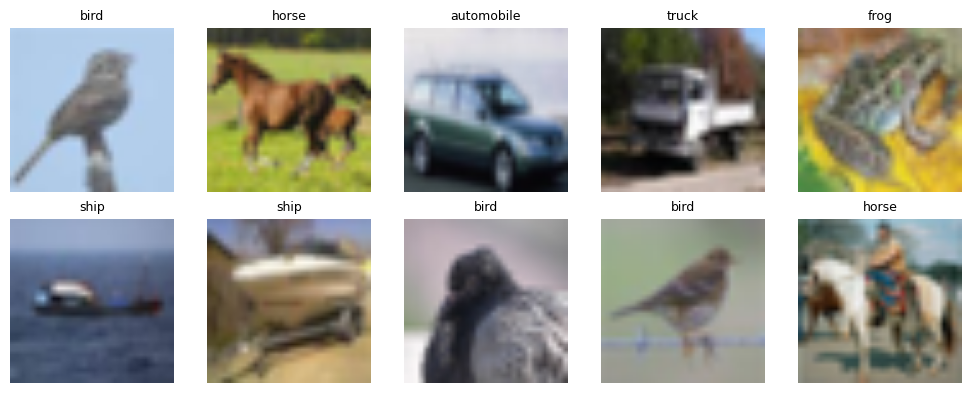

In [31]:
import matplotlib.pyplot as plt

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def denormalize(image):
    return (image.cpu() * std_tensor + mean_tensor).clamp(0, 1)  # undo ImageNet normalization for display

sample_images, sample_labels = next(iter(val_loader))
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(denormalize(sample_images[i]).permute(1, 2, 0))  # CHW -> HWC
    plt.title(class_names[sample_labels[i]], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(dirs["figures"], "cifar_samples.png"), dpi=120)
plt.show()

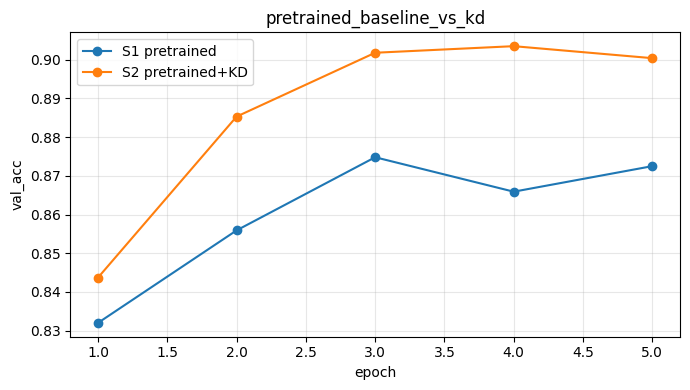

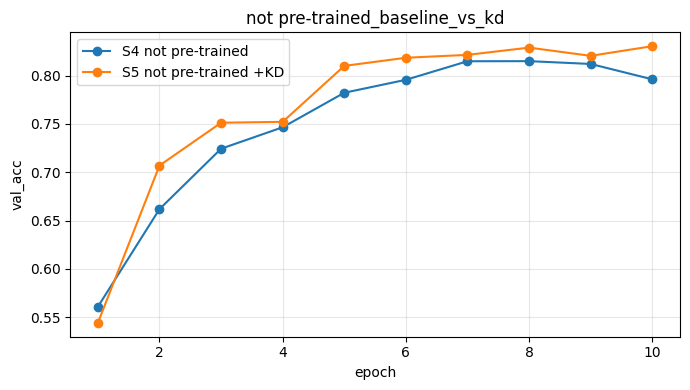

In [33]:
def plot_curves(histories_by_label, metric, title):
    plt.figure(figsize=(7, 4))
    for label, history in histories_by_label.items():
        plt.plot(range(1, len(history[metric]) + 1), history[metric], marker="o", label=label)
    plt.xlabel("epoch"); plt.ylabel(metric); plt.title(title)
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(dirs["figures"], f"{title}.png"), dpi=120)
    plt.show()

plot_curves({"S1 pretrained": s1_history, "S2 pretrained+KD": s2_history},
            "val_acc", "pretrained_baseline_vs_kd")
plot_curves({"S4 not pre-trained": s4_history, "S5 not pre-trained +KD": s5_history},
            "val_acc", "not pre-trained_baseline_vs_kd")

## Section 8 - Score + Feature-level Knowledge Distillation
In addition to matching the teacher's output scores, the student now also
mimics an intermediate feature map (layer4). Since teacher and student have
different channel counts (2048 vs 512), a 1x1 conv "adapter" projects the
student features to the teacher dimension before computing the feature loss
(MSE). The adapter is trained jointly with the student but is NOT used at
inference — it only serves the feature loss.

Total loss = (1 - alpha) * CE + alpha * T^2 * KL(scores) + lambda_feat * MSE(features)

**Feature extraction hook and channel adapter**

A forward hook stores the output of a chosen layer during the forward pass,
without modifying the model. The adapter is a 1x1 convolution mapping the
student channels to the teacher channels (spatial size already matches).

In [34]:
class FeatureHook:
    """Stores the output of a module during forward (no model rewrite needed)."""
    def __init__(self, module):
        self.features = None
        self.handle = module.register_forward_hook(self._hook)
    def _hook(self, module, inputs, output):
        self.features = output
    def close(self):
        self.handle.remove()

def build_feature_adapter(student_channels, teacher_channels):
    # 1x1 conv: align student feature channels to the teacher's (spatial dims already match)
    return nn.Conv2d(student_channels, teacher_channels, kernel_size=1).to(device)

**Training loop with the three-term loss**
The teacher runs frozen (no grad). We capture both feature maps via hooks,
project the student features with the adapter, and add an MSE feature loss to
the score-level distillation loss. The optimizer updates the student AND the
adapter.

We log the three *weighted* loss contributions separately. This is a first
diagnostic of their balance (note: loss magnitude is not gradient magnitude).
If the feature term dominates from epoch 1 and hurts accuracy, lower lambda_feat.

In [35]:
def train_one_epoch_kd_features(student, teacher, adapter, loader, optimizer, device,
                                temperature, alpha, lambda_feat,
                                student_layer, teacher_layer):
    student.train(); teacher.eval()
    student_hook = FeatureHook(student_layer)
    teacher_hook = FeatureHook(teacher_layer)
    totals = {"loss": 0.0, "ce": 0.0, "kd": 0.0, "feat": 0.0}
    correct, total = 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.no_grad():
            teacher_logits = teacher(images)
            teacher_features = teacher_hook.features
        optimizer.zero_grad()
        student_logits = student(images)
        student_features = student_hook.features

        # Three components kept explicit for monitoring
        ce_loss = F.cross_entropy(student_logits, labels)
        student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
        teacher_probs     = F.softmax(teacher_logits / temperature, dim=1)
        kd_loss = F.kl_div(student_log_probs, teacher_probs, reduction="batchmean") * (temperature ** 2)
        feature_loss = F.mse_loss(adapter(student_features), teacher_features)

        # Weighted total (the weights are what actually balances the objective)
        weighted_ce   = (1 - alpha) * ce_loss
        weighted_kd   = alpha * kd_loss
        weighted_feat = lambda_feat * feature_loss
        loss = weighted_ce + weighted_kd + weighted_feat

        loss.backward()
        optimizer.step()

        batch = images.size(0)
        totals["loss"] += loss.item()          * batch
        totals["ce"]   += weighted_ce.item()   * batch   # weighted contributions
        totals["kd"]   += weighted_kd.item()   * batch
        totals["feat"] += weighted_feat.item() * batch
        correct += (student_logits.argmax(1) == labels).sum().item()
        total += batch
    student_hook.close(); teacher_hook.close()
    for key in totals:
        totals[key] /= total
    return totals, correct / total


def fit_kd_features(student, teacher, train_loader, val_loader, config, run_name, epochs,
                    student_layer, teacher_layer, student_channels, teacher_channels):
    adapter = build_feature_adapter(student_channels, teacher_channels)
    optimizer = torch.optim.Adam(list(student.parameters()) + list(adapter.parameters()),
                                 lr=config["learning_rate"])
    criterion_eval = nn.CrossEntropyLoss()
    temperature, alpha, lambda_feat = config["temperature"], config["alpha"], config["lambda_feat"]
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0
    for epoch in range(epochs):
        start = time.time()
        train_totals, train_acc = train_one_epoch_kd_features(
            student, teacher, adapter, train_loader, optimizer, device,
            temperature, alpha, lambda_feat, student_layer, teacher_layer)
        val_loss, val_acc = evaluate(student, val_loader, criterion_eval, device)
        history["train_loss"].append(train_totals["loss"]); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss);               history["val_acc"].append(val_acc)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint(student, f"{run_name}_best", {"epoch": epoch, "val_acc": val_acc})
        print(f"epoch {epoch+1}/{epochs} | train acc {train_acc:.3f} | "
              f"CE {train_totals['ce']:.3f}  KD {train_totals['kd']:.3f}  Feat {train_totals['feat']:.3f} | "
              f"val acc {val_acc:.3f} | {time.time()-start:.0f}s")
    return history, best_val_acc

In [36]:
# S3 : pretrained student + KD scores + features
student_s3 = build_resnet18_student(pretrained=True).to(device)
s3_history, s3_best_val = fit_kd_features(
    student_s3, teacher, train_loader, val_loader, config,
    run_name="S3_pretrained_kd_features", epochs=config["epochs_pretrained"],
    student_layer=student_s3.layer4, teacher_layer=teacher.layer4,
    student_channels=512, teacher_channels=2048)
load_checkpoint(student_s3, "S3_pretrained_kd_features_best", device)
_, s3_test_acc = evaluate(student_s3, test_loader, nn.CrossEntropyLoss(), device)
record_result("S3_pretrained_kd_features", s3_best_val, s3_test_acc)
print(f"S3- best val: {s3_best_val:.4f} | test: {s3_test_acc:.4f}")

epoch 1/5 | train acc 0.835 | CE 0.258  KD 0.581  Feat 0.847 | val acc 0.843 | 57s
epoch 2/5 | train acc 0.907 | CE 0.139  KD 0.309  Feat 0.598 | val acc 0.886 | 55s
epoch 3/5 | train acc 0.927 | CE 0.108  KD 0.242  Feat 0.529 | val acc 0.884 | 55s
epoch 4/5 | train acc 0.941 | CE 0.087  KD 0.203  Feat 0.488 | val acc 0.899 | 55s
epoch 5/5 | train acc 0.952 | CE 0.072  KD 0.170  Feat 0.456 | val acc 0.909 | 57s
S3 — best val: 0.9095 | test: 0.9084


In [38]:
# S6 : scratch student + KD scores + features
student_s6 = build_resnet18_student(pretrained=False).to(device)
s6_history, s6_best_val = fit_kd_features(
    student_s6, teacher, train_loader, val_loader, config,
    run_name="S6_scr_kd_features", epochs=config["epochs_scratch"],
    student_layer=student_s6.layer4, teacher_layer=teacher.layer4,
    student_channels=512, teacher_channels=2048)
load_checkpoint(student_s6, "S6_scratch_kd_features_best", device)
_, s6_test_acc = evaluate(student_s6, test_loader, nn.CrossEntropyLoss(), device)
record_result("S6_scratch_kd_features", s6_best_val, s6_test_acc)
print(f"S6- best val: {s6_best_val:.4f} | test: {s6_test_acc:.4f}")

epoch 1/10 | train acc 0.530 | CE 0.690  KD 1.785  Feat 1.088 | val acc 0.616 | 55s
epoch 2/10 | train acc 0.714 | CE 0.440  KD 1.025  Feat 0.844 | val acc 0.668 | 54s
epoch 3/10 | train acc 0.785 | CE 0.330  KD 0.738  Feat 0.740 | val acc 0.757 | 56s
epoch 4/10 | train acc 0.824 | CE 0.267  KD 0.589  Feat 0.678 | val acc 0.779 | 55s
epoch 5/10 | train acc 0.855 | CE 0.217  KD 0.478  Feat 0.634 | val acc 0.827 | 55s
epoch 6/10 | train acc 0.876 | CE 0.186  KD 0.411  Feat 0.603 | val acc 0.826 | 55s
epoch 7/10 | train acc 0.895 | CE 0.157  KD 0.350  Feat 0.574 | val acc 0.844 | 54s
epoch 8/10 | train acc 0.909 | CE 0.134  KD 0.306  Feat 0.553 | val acc 0.851 | 56s
epoch 9/10 | train acc 0.924 | CE 0.113  KD 0.261  Feat 0.531 | val acc 0.850 | 55s
epoch 10/10 | train acc 0.936 | CE 0.097  KD 0.232  Feat 0.515 | val acc 0.860 | 58s
S6- best val: 0.8597 | test: 0.8254


**Persistence**

In [63]:
import json

with open(os.path.join(dirs["results"], "results.json"), "w") as file:
    json.dump(results, file, indent=2)

all_histories = {"T0": teacher_history, "S1": s1_history, "S2": s2_history,
                 "S4": s4_history, "S5": s5_history}
with open(os.path.join(dirs["results"], "histories.json"), "w") as file:
    json.dump(all_histories, file, indent=2)
print("Saved results and histories to Drive.")

Saved results and histories to Drive.


## Section 9 -Comparisons


**Strategy 1 vs Strategy 2**

All seven ResNet runs side by side (test accuracy and best validation).

### 9a-bis — Add macro-F1 to the classification metrics
Top-1 accuracy is already reported. We add macro-F1 (computed on the test set
from the best checkpoint of each model). On a balanced dataset it stays close
to accuracy, but confirms no class is systematically sacrificed.

In [42]:
from sklearn.metrics import accuracy_score, f1_score

@torch.no_grad()
def evaluate_classifier(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        preds = model(images).argmax(1).cpu()
        all_preds.append(preds); all_labels.append(labels)
    all_preds  = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    return {"accuracy": accuracy_score(all_labels, all_preds),
            "f1_macro": f1_score(all_labels, all_preds, average="macro")}

# Each model object currently holds its best checkpoint (loaded right after training)
trained_models = {
    "T0_teacher_resnet50":      teacher,
    "S1_resnet18_pretrained":   student_s1,
    "S2_pretrained_kd_scores":  student_s2,
    "S3_pretrained_kd_features": student_s3,
    "S4_resnet18_scratch":      student_s4,
    "S5_scratch_kd_scores":     student_s5,
    "S6_scratch_kd_features":   student_s6,
}
for run_name, model in trained_models.items():
    results[run_name]["test_f1_macro"] = round(evaluate_classifier(model, test_loader, device)["f1_macro"], 4)
print("Macro-F1 added to results.")

Macro-F1 added to results.


In [43]:
import pandas as pd

recap = pd.DataFrame(results).T[["best_val_acc", "test_acc", "test_f1_macro"]]
recap = recap.sort_values("test_acc", ascending=False).round(4)
recap.to_csv(os.path.join(dirs["results"], "recap_accuracy.csv"))
recap

,best_val_acc,test_acc,test_f1_macro
T0_teacher_resnet50,0.9113,0.9084,0.9077
S3_pretrained_kd_features,0.9095,0.9084,0.9085
S2_pretrained_kd_scores,0.9035,0.8985,0.8995
S1_resnet18_pretrained,0.8748,0.8721,0.8709
S5_scratch_kd_scores,0.8305,0.8286,0.8276
S6_scratch_kd_features,0.8597,0.8254,0.8252
S4_resnet18_scratch,0.8150,0.8130,0.8129


**Study A: teacher-student distances**
For each trained student, measure how close its outputs are to the teacher's,
on the test set, using several distance metrics (no retraining). Lower MSE /
RMSE / MAE / KL means closer; higher cosine similarity means closer. This
checks whether distillation actually brings students closer to the teacher.

In [46]:
@torch.no_grad()
def collect_logits(model, loader, device):
    model.eval()
    logits_list = []
    for images, _ in loader:
        logits_list.append(model(images.to(device, non_blocking=True)).cpu())
    return torch.cat(logits_list)

def teacher_student_distances(teacher_logits, student_logits, temperature=1.0):
    mse = F.mse_loss(student_logits, teacher_logits).item()
    mae = F.l1_loss(student_logits, teacher_logits).item()
    teacher_probs     = F.softmax(teacher_logits / temperature, dim=1)
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    kl = F.kl_div(student_log_probs, teacher_probs, reduction="batchmean").item()  # KL(teacher || student)
    cosine = F.cosine_similarity(student_logits, teacher_logits, dim=1).mean().item()
    return {"MSE": mse, "RMSE": mse ** 0.5, "MAE": mae, "KL": kl, "cosine_sim": cosine}


In [48]:

teacher_logits_test = collect_logits(teacher, test_loader, device)

students_for_distance = {
    "S1_pretrained":          student_s1, "S2_kd_scores":          student_s2,
    "S3_kd_features":         student_s3, "S4_not_pre-trained":            student_s4,
    "S5_not_pre-trained_kd_scores":   student_s5, "S6_scratch_kd_features": student_s6,
}
distance_rows = {}
for name, model in students_for_distance.items():
    student_logits_test = collect_logits(model, test_loader, device)
    distance_rows[name] = teacher_student_distances(teacher_logits_test, student_logits_test)

distances_table = pd.DataFrame(distance_rows).T.round(4)
distances_table.to_csv(os.path.join(dirs["results"], "teacher_student_distances.csv"))
distances_table

,MSE,RMSE,MAE,KL,cosine_sim
S1_pretrained,14.3155,3.7836,3.1976,0.4073,0.7304
S2_kd_scores,11.4157,3.3787,3.0238,0.2732,0.7767
S3_kd_features,7.0785,2.6606,2.3310,0.2267,0.8831
S4_not_pre-trained,10.8280,3.2906,2.6219,0.5298,0.8127
S5_not_pre-trained_kd_scores,8.9675,2.9946,2.4857,0.4538,0.8331
S6_scratch_kd_features,7.2825,2.6986,2.1772,0.4451,0.8772


## Section 10 — Efficiency metrics


Parameters, model size (MB), MACs/FLOPs, and inference latency/throughput.
These depend only on the architecture and input resolution (not the weights),
so one measurement for ResNet50 and one for ResNet18 cover every run.

In [49]:
!pip install thop -q
from thop import profile

def compute_efficiency_metrics(model, image_size, device):
    model.eval()
    total_params, _ = count_parameters(model)
    size_mb = total_params * 4 / (1024 ** 2)              # float32 -> 4 bytes per parameter
    dummy = torch.randn(1, 3, image_size, image_size).to(device)
    macs, _ = profile(model, inputs=(dummy,), verbose=False)
    return {"params": total_params, "size_MB": round(size_mb, 2),
            "macs": int(macs), "flops": int(2 * macs)}    # 1 MAC = 2 FLOPs

@torch.no_grad()
def benchmark_inference(model, image_size, device, batch_size=1, n_warmup=10, n_runs=50):
    model.eval()
    dummy = torch.randn(batch_size, 3, image_size, image_size).to(device)
    for _ in range(n_warmup):                              # warmup (CUDA kernels, caches)
        _ = model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(n_runs):
        _ = model(dummy)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start
    return {"latency_ms": round(elapsed / n_runs * 1000, 2),
            "fps": round(batch_size * n_runs / elapsed, 1)}

In [50]:
# Efficiency depends on architecture + resolution only -> measure ResNet50 and ResNet18 once each
efficiency = {}
for arch_name, model in [("ResNet50 (teacher)", teacher),
                         ("ResNet18 (students)", student_s1)]:
    metrics = compute_efficiency_metrics(model, config["resolution"], device)
    metrics.update(benchmark_inference(model, config["resolution"], device))
    efficiency[arch_name] = metrics

efficiency_table = pd.DataFrame(efficiency).T
efficiency_table.to_csv(os.path.join(dirs["results"], "efficiency.csv"))
efficiency_table

,params,size_MB,macs,flops,latency_ms,fps
ResNet50 (teacher),23528522.0,89.75,758904832.0,1.517810e+09,6.34,157.7
ResNet18 (students),11181642.0,42.65,334938112.0,6.698762e+08,2.36,423.9


## Section 11 - Custom CNN teacher and compressed students
We reuse the entire pipeline with a small custom CNN instead of ResNet.
Teacher: 4 conv blocks (32-64-128-256), GAP, linear head. Students: same
architecture with halved/quartered widths. Trained from scratch (no ImageNet
pretraining is possible here — a documented methodological difference).
Same 96x96 pipeline as the ResNet runs, so FLOPs stay comparable.

In [52]:
class CustomCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128, 256), num_classes=10):
        super().__init__()
        widths = [3] + list(channels)
        blocks = []
        for i in range(len(channels)):
            blocks += [nn.Conv2d(widths[i], widths[i+1], kernel_size=3, padding=1),
                       nn.BatchNorm2d(widths[i+1]),
                       nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
        self.features   = nn.Sequential(*blocks)          # hook target for feature-level KD
        self.pool       = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(channels[-1], num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

In [53]:
custom_teacher = CustomCNN(channels=(32, 64, 128, 256)).to(device)
c0_history, c0_best_val = fit(custom_teacher, train_loader, val_loader, config,
                              run_name="C0_custom_teacher", epochs=config["epochs_scratch"])

load_checkpoint(custom_teacher, "C0_custom_teacher_best", device)
_, c0_test_acc = evaluate(custom_teacher, test_loader, nn.CrossEntropyLoss(), device)
record_result("C0_custom_teacher", c0_best_val, c0_test_acc)

# Efficiency of the custom teacher (for later comparison)
c0_eff = compute_efficiency_metrics(custom_teacher, config["resolution"], device)
print(f"C0 custom teacher - test acc: {c0_test_acc:.4f} | params: {c0_eff['params']:,} | FLOPs: {c0_eff['flops']:,}")

epoch 1/10 | train loss 1.479 acc 0.466 | val loss 1.638 acc 0.413 | 41s
epoch 2/10 | train loss 1.158 acc 0.592 | val loss 1.389 acc 0.508 | 35s
epoch 3/10 | train loss 1.031 acc 0.636 | val loss 1.055 acc 0.629 | 36s
epoch 4/10 | train loss 0.933 acc 0.674 | val loss 1.020 acc 0.636 | 34s
epoch 5/10 | train loss 0.869 acc 0.694 | val loss 1.300 acc 0.564 | 34s
epoch 6/10 | train loss 0.812 acc 0.719 | val loss 0.928 acc 0.684 | 35s
epoch 7/10 | train loss 0.762 acc 0.736 | val loss 1.070 acc 0.639 | 34s
epoch 8/10 | train loss 0.716 acc 0.752 | val loss 0.985 acc 0.661 | 33s
epoch 9/10 | train loss 0.680 acc 0.767 | val loss 0.905 acc 0.695 | 34s
epoch 10/10 | train loss 0.649 acc 0.779 | val loss 0.759 acc 0.744 | 35s
C0 custom teacher — test acc: 0.7334 | params: 391,946 | FLOPs: 275,176,960


In [54]:
# It was still improving at epoch 10 -> train 10 more epochs (fresh optimizer, warm weights)
_, c0_best_val = fit(custom_teacher, train_loader, val_loader, config,
                     run_name="C0_custom_teacher", epochs=10)
load_checkpoint(custom_teacher, "C0_custom_teacher_best", device)
_, c0_test_acc = evaluate(custom_teacher, test_loader, nn.CrossEntropyLoss(), device)
record_result("C0_custom_teacher", c0_best_val, c0_test_acc)
print(f"C0 custom teacher (20 epochs, 10+10) - test acc: {c0_test_acc:.4f}")

epoch 1/10 | train loss 0.624 acc 0.785 | val loss 1.035 acc 0.662 | 39s
epoch 2/10 | train loss 0.590 acc 0.799 | val loss 0.724 acc 0.749 | 34s
epoch 3/10 | train loss 0.565 acc 0.806 | val loss 0.810 acc 0.724 | 36s
epoch 4/10 | train loss 0.542 acc 0.813 | val loss 0.717 acc 0.754 | 35s
epoch 5/10 | train loss 0.517 acc 0.824 | val loss 0.948 acc 0.687 | 34s
epoch 6/10 | train loss 0.497 acc 0.829 | val loss 0.916 acc 0.690 | 34s
epoch 7/10 | train loss 0.476 acc 0.837 | val loss 0.725 acc 0.756 | 35s
epoch 8/10 | train loss 0.462 acc 0.842 | val loss 0.607 acc 0.791 | 34s
epoch 9/10 | train loss 0.435 acc 0.854 | val loss 0.669 acc 0.772 | 34s
epoch 10/10 | train loss 0.415 acc 0.859 | val loss 0.787 acc 0.739 | 34s
C0 custom teacher (20 epochs, 10+10) — test acc: 0.7803


**Compressed Students**

In [55]:
custom_configs = {"custom_div2": (16, 32, 64, 128),
                  "custom_div4": (8, 16, 32, 64)}
teacher_last_channels = 256
custom_efficiency = {"C0_custom_teacher": compute_efficiency_metrics(custom_teacher, config["resolution"], device)}

def run_custom_student(tag, channels):
    student_last = channels[-1]

    # 1) baseline (CE only)
    model = CustomCNN(channels).to(device)
    _, best_val = fit(model, train_loader, val_loader, config,
                      run_name=f"{tag}_baseline", epochs=config["epochs_scratch"])
    load_checkpoint(model, f"{tag}_baseline_best", device)
    _, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
    record_result(f"{tag}_baseline", best_val, test_acc)
    custom_efficiency[tag] = compute_efficiency_metrics(model, config["resolution"], device)  # once per arch

    # 2) KD scores
    model = CustomCNN(channels).to(device)
    _, best_val = fit_kd_scores(model, custom_teacher, train_loader, val_loader, config,
                                run_name=f"{tag}_kd_scores", epochs=config["epochs_scratch"])
    load_checkpoint(model, f"{tag}_kd_scores_best", device)
    _, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
    record_result(f"{tag}_kd_scores", best_val, test_acc)

    # 3) KD scores + features
    model = CustomCNN(channels).to(device)
    _, best_val = fit_kd_features(model, custom_teacher, train_loader, val_loader, config,
                                  run_name=f"{tag}_kd_features", epochs=config["epochs_scratch"],
                                  student_layer=model.features, teacher_layer=custom_teacher.features,
                                  student_channels=student_last, teacher_channels=teacher_last_channels)
    load_checkpoint(model, f"{tag}_kd_features_best", device)
    _, test_acc = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
    record_result(f"{tag}_kd_features", best_val, test_acc)

for tag, channels in custom_configs.items():
    print(f"\n===== {tag} {channels} =====")
    run_custom_student(tag, channels)


===== custom_div2 (16, 32, 64, 128) =====
epoch 1/10 | train loss 1.531 acc 0.452 | val loss 1.427 acc 0.474 | 45s
epoch 2/10 | train loss 1.242 acc 0.559 | val loss 1.353 acc 0.511 | 33s
epoch 3/10 | train loss 1.125 acc 0.603 | val loss 1.147 acc 0.585 | 33s
epoch 4/10 | train loss 1.046 acc 0.631 | val loss 1.206 acc 0.564 | 33s
epoch 5/10 | train loss 0.977 acc 0.657 | val loss 1.105 acc 0.603 | 33s
epoch 6/10 | train loss 0.931 acc 0.675 | val loss 1.171 acc 0.612 | 32s
epoch 7/10 | train loss 0.888 acc 0.691 | val loss 1.034 acc 0.650 | 32s
epoch 8/10 | train loss 0.855 acc 0.701 | val loss 1.023 acc 0.651 | 33s
epoch 9/10 | train loss 0.819 acc 0.715 | val loss 0.969 acc 0.667 | 33s
epoch 10/10 | train loss 0.794 acc 0.725 | val loss 0.886 acc 0.684 | 32s
epoch 1/10 | train loss 1.870 acc 0.454 | val loss 1.370 acc 0.515 | 33s
epoch 2/10 | train loss 1.291 acc 0.574 | val loss 1.263 acc 0.558 | 34s
epoch 3/10 | train loss 1.057 acc 0.624 | val loss 1.209 acc 0.577 | 34s
epoch 4

In [56]:
#Results

custom_names = ["C0_custom_teacher",
                "custom_div2_baseline", "custom_div2_kd_scores", "custom_div2_kd_features",
                "custom_div4_baseline", "custom_div4_kd_scores", "custom_div4_kd_features"]
custom_recap = pd.DataFrame({k: results[k] for k in custom_names if k in results}).T.round(4)
custom_recap.to_csv(os.path.join(dirs["results"], "custom_recap.csv"))

custom_eff_table = pd.DataFrame(custom_efficiency).T
ref_params = custom_efficiency["C0_custom_teacher"]["params"]
ref_flops  = custom_efficiency["C0_custom_teacher"]["flops"]
custom_eff_table["param_ratio"] = (ref_params / custom_eff_table["params"]).round(2)
custom_eff_table["flops_ratio"] = (ref_flops / custom_eff_table["flops"]).round(2)
custom_eff_table.to_csv(os.path.join(dirs["results"], "custom_efficiency.csv"))
print(custom_recap); print(custom_eff_table)

                         best_val_acc  test_acc
C0_custom_teacher              0.7914    0.7803
custom_div2_baseline           0.6842    0.6815
custom_div2_kd_scores          0.7015    0.7051
custom_div2_kd_features        0.7115    0.7066
custom_div4_baseline           0.6184    0.6220
custom_div4_kd_scores          0.6538    0.6538
custom_div4_kd_features        0.6649    0.6583
                     params  size_MB         macs        flops  param_ratio  \
C0_custom_teacher  391946.0     1.50  137588480.0  275176960.0         1.00   
custom_div2         99210.0     0.38   36943744.0   73887488.0         3.95   
custom_div4         25418.0     0.10   10509248.0   21018496.0        15.42   

                   flops_ratio  
C0_custom_teacher         1.00  
custom_div2               3.72  
custom_div4              13.09  


## Section 12 - Synthesis figures and report
Consolidated accuracy vs cost view across all runs, and the distillation
progression per group. Figures are saved under figures/ for the report.

In [58]:
import numpy as np

# Map each run to its architecture's efficiency (ResNet18 shared by S1..S6)
arch_eff = {
    "T0_teacher_resnet50":      efficiency["ResNet50 (teacher)"],
    **{name: efficiency["ResNet18 (students)"] for name in
       ["S1_resnet18_pretrained","S2_pretrained_kd_scores","S3_pretrained_kd_features",
        "S4_resnet18_scratch","S5_scratch_kd_scores","S6_scratch_kd_features"]},
    "C0_custom_teacher":        custom_efficiency["C0_custom_teacher"],
    **{name: custom_efficiency["custom_div2"] for name in
       ["custom_div2_baseline","custom_div2_kd_scores","custom_div2_kd_features"]},
    **{name: custom_efficiency["custom_div4"] for name in
       ["custom_div4_baseline","custom_div4_kd_scores","custom_div4_kd_features"]},
}
master = pd.DataFrame([{"run": r, "test_acc": results[r]["test_acc"],
                        "params": arch_eff[r]["params"], "flops": arch_eff[r]["flops"]}
                       for r in arch_eff]).set_index("run")
master.to_csv(os.path.join(dirs["results"], "master_table.csv"))
master

,test_acc,params,flops
run,,,
T0_teacher_resnet50,0.9084,23528522,1517809664
S1_resnet18_pretrained,0.8721,11181642,669876224
S2_pretrained_kd_scores,0.8985,11181642,669876224
S3_pretrained_kd_features,0.9084,11181642,669876224
S4_resnet18_scratch,0.8130,11181642,669876224
S5_scratch_kd_scores,0.8286,11181642,669876224
S6_scratch_kd_features,0.8254,11181642,669876224
C0_custom_teacher,0.7803,391946,275176960
custom_div2_baseline,0.6815,99210,73887488


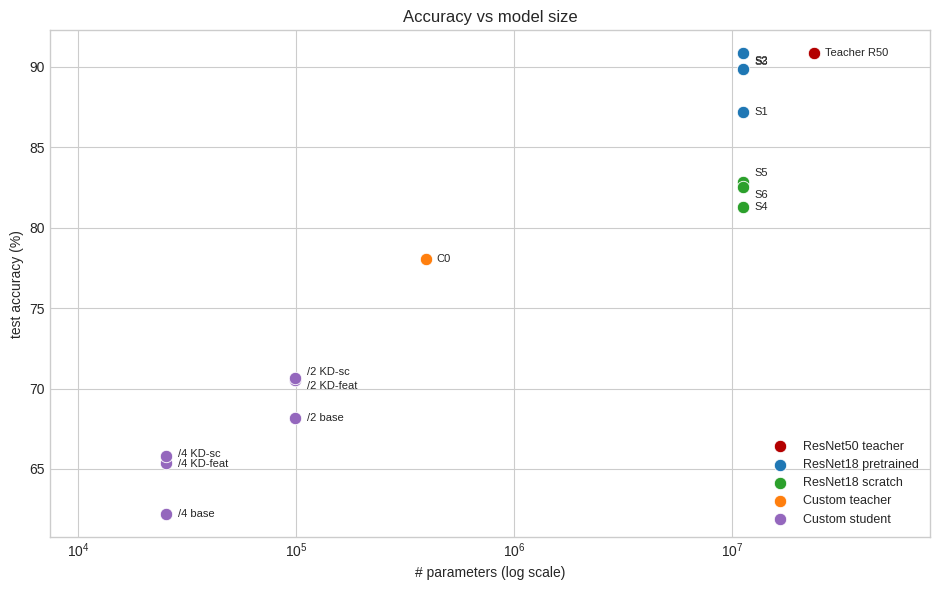

In [60]:
# Figure 1 : accuracy vs number of parameters (the efficiency/performance tradeoff)




import matplotlib.pyplot as plt

try:
    plt.style.use("seaborn-v0_8-whitegrid")   # cleaner grid style
except OSError:
    plt.style.use("ggplot")

short_label = {
    "T0_teacher_resnet50": "Teacher R50",
    "S1_resnet18_pretrained": "S1", "S2_pretrained_kd_scores": "S2", "S3_pretrained_kd_features": "S3",
    "S4_resnet18_scratch": "S4", "S5_scratch_kd_scores": "S5", "S6_scratch_kd_features": "S6",
    "C0_custom_teacher": "C0",
    "custom_div2_baseline": "/2 base", "custom_div2_kd_scores": "/2 KD-sc", "custom_div2_kd_features": "/2 KD-feat",
    "custom_div4_baseline": "/4 base", "custom_div4_kd_scores": "/4 KD-sc", "custom_div4_kd_features": "/4 KD-feat",
}
category = {
    "T0_teacher_resnet50": "ResNet50 teacher",
    "S1_resnet18_pretrained": "ResNet18 pretrained", "S2_pretrained_kd_scores": "ResNet18 pretrained",
    "S3_pretrained_kd_features": "ResNet18 pretrained",
    "S4_resnet18_scratch": "ResNet18 scratch", "S5_scratch_kd_scores": "ResNet18 scratch",
    "S6_scratch_kd_features": "ResNet18 scratch",
    "C0_custom_teacher": "Custom teacher",
    "custom_div2_baseline": "Custom student", "custom_div2_kd_scores": "Custom student",
    "custom_div2_kd_features": "Custom student",
    "custom_div4_baseline": "Custom student", "custom_div4_kd_scores": "Custom student",
    "custom_div4_kd_features": "Custom student",
}
colors = {"ResNet50 teacher": "#b30000", "ResNet18 pretrained": "#1f77b4",
          "ResNet18 scratch": "#2ca02c", "Custom teacher": "#ff7f0e", "Custom student": "#9467bd"}

fig, ax = plt.subplots(figsize=(9.5, 6))
seen = set()
# small vertical nudges for points that share the same x and nearly the same y
nudge = {"S2": 6, "S3": -6, "S5": 6, "S6": -6, "/2 KD-sc": 6, "/2 KD-feat": -6,
         "/4 KD-sc": 6, "/4 KD-feat": -6}
for run, row in master.iterrows():
    cat = category[run]; label = short_label[run]
    ax.scatter(row["params"], row["test_acc"] * 100, s=80, color=colors[cat], zorder=3,
               edgecolor="white", linewidth=0.6, label=cat if cat not in seen else None)
    seen.add(cat)
    ax.annotate(label, (row["params"], row["test_acc"] * 100),
                xytext=(8, nudge.get(label, 0)), textcoords="offset points",
                fontsize=8, va="center")
ax.set_xscale("log")
ax.set_xlabel("# parameters (log scale)"); ax.set_ylabel("test accuracy (%)")
ax.set_title("Accuracy vs model size")
ax.legend(loc="lower right", framealpha=0.9, fontsize=9)
ax.margins(x=0.18)   # room for the right-side labels
plt.tight_layout()
plt.savefig(os.path.join(dirs["figures"], "accuracy_vs_params.png"), dpi=150, bbox_inches="tight")
plt.show()

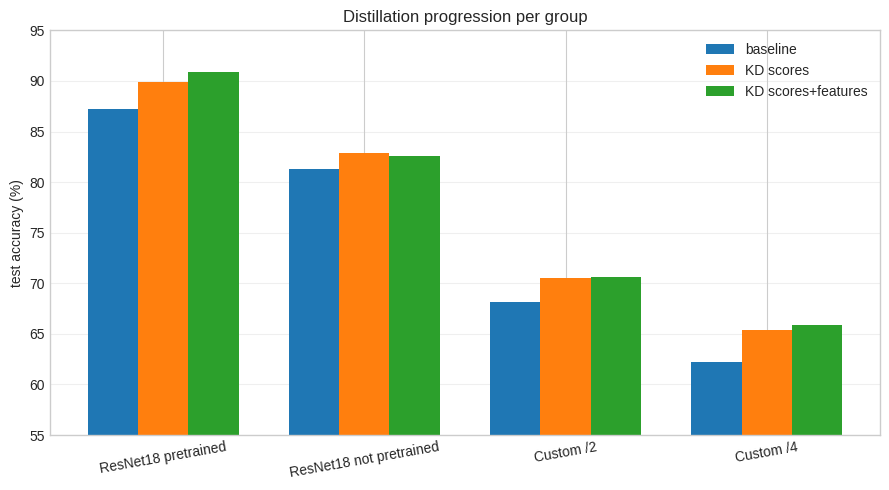

In [62]:
# Figure 2 — distillation progression per group (baseline -> scores -> features)
groups = {
    "ResNet18 pretrained": ["S1_resnet18_pretrained","S2_pretrained_kd_scores","S3_pretrained_kd_features"],
    "ResNet18 not pretrained":    ["S4_resnet18_scratch","S5_scratch_kd_scores","S6_scratch_kd_features"],
    "Custom /2":           ["custom_div2_baseline","custom_div2_kd_scores","custom_div2_kd_features"],
    "Custom /4":           ["custom_div4_baseline","custom_div4_kd_scores","custom_div4_kd_features"],
}
levels = ["baseline", "KD scores", "KD scores+features"]
x = np.arange(len(groups)); width = 0.25
plt.figure(figsize=(9, 5))
for i, level in enumerate(levels):
    values = [results[runs[i]]["test_acc"] * 100 for runs in groups.values()]
    plt.bar(x + (i - 1) * width, values, width, label=level)
plt.xticks(x, list(groups.keys()), rotation=10); plt.ylabel("test accuracy (%)")
plt.title("Distillation progression per group"); plt.legend(); plt.ylim(55, 95)
plt.grid(True, axis="y", alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(dirs["figures"], "kd_progression.png"), dpi=120); plt.show()